# RNN, LSTM, GRU — Project 1
## Beginner News Text Classification & Model Comparison

**Goal:** Train **SimpleRNN, LSTM, and GRU** on the same AG News dataset and compare them using the same preprocessing, train/validation/test split, optimizer, epochs, and evaluation methods.

Dataset: **AG News**, a 4-class news classification dataset: World, Sports, Business, Sci/Tech. A commonly used version has 120,000 training and 7,600 test examples. citeturn0search0

This notebook intentionally uses basic Keras code and avoids Attention/Transformers so the three recurrent models are easy to understand.

## Dataset and reference projects

AG News labels:
- 0 → World
- 1 → Sports
- 2 → Business
- 3 → Sci/Tech

Useful GitHub references for further study:
- [AG News LSTM](https://github.com/Maulanaaz/ag-news-classification-lstm)
- [LSTM + GRU AG News](https://github.com/dgholamian/news-classification-attention-models)
- [Progressive AG News classification](https://github.com/yousefsameh2005/news-topic-classification-progressive)

The repositories above contain more advanced variations; this notebook stays at beginner level.

In [1]:
# 1. Install/import libraries
# Uncomment if packages are missing:
# !pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

import os
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
# 2. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Seed:", SEED)

Seed: 42


## 3. Download AG News

We use a public GitHub mirror containing `train.csv` and `test.csv`.

The test set is kept untouched until final evaluation.

In [3]:
# 3. Download dataset files
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

train_url = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv"
test_url = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/test.csv"

train_path = os.path.join(DATA_DIR, "train.csv")
test_path = os.path.join(DATA_DIR, "test.csv")

if not os.path.exists(train_path):
    urllib.request.urlretrieve(train_url, train_path)
if not os.path.exists(test_path):
    urllib.request.urlretrieve(test_url, test_path)

print(train_path, test_path)

data\train.csv data\test.csv


In [4]:
# 4. Load CSV
columns = ["label", "title", "description"]

train_df = pd.read_csv(train_path, header=None, names=columns)
test_df = pd.read_csv(test_path, header=None, names=columns)

# Convert labels 1-4 -> 0-3
train_df["label"] -= 1
test_df["label"] -= 1

# Combine title + description
train_df["text"] = train_df["title"].fillna("") + " " + train_df["description"].fillna("")
test_df["text"] = test_df["title"].fillna("") + " " + test_df["description"].fillna("")

print("Train:", train_df.shape)
print("Test :", test_df.shape)
train_df.head()

Train: (120000, 4)
Test : (7600, 4)


,label,title,description,text
0,2,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",Wall St. Bears Claw Back Into the Black (Reute...
1,2,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,Carlyle Looks Toward Commercial Aerospace (Reu...
2,2,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,Oil and Economy Cloud Stocks' Outlook (Reuters...
3,2,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...,Iraq Halts Oil Exports from Main Southern Pipe...
4,2,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco...","Oil prices soar to all-time record, posing new..."


label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64


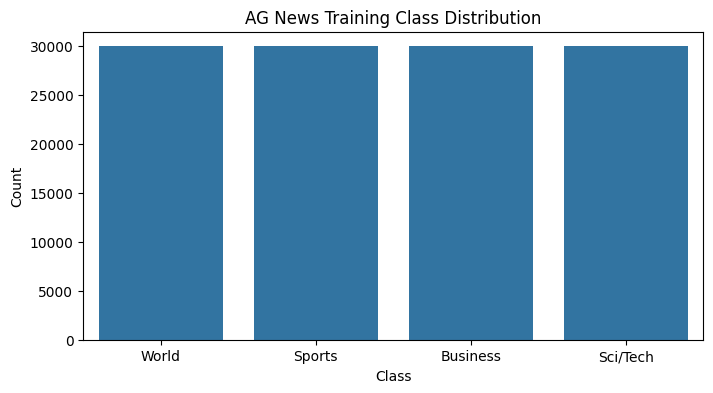

In [5]:
# 5. Basic EDA: class distribution
label_names = ["World", "Sports", "Business", "Sci/Tech"]

print(train_df["label"].value_counts().sort_index())

plt.figure(figsize=(8,4))
sns.countplot(x=train_df["label"], order=[0,1,2,3])
plt.xticks(range(4), label_names)
plt.title("AG News Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

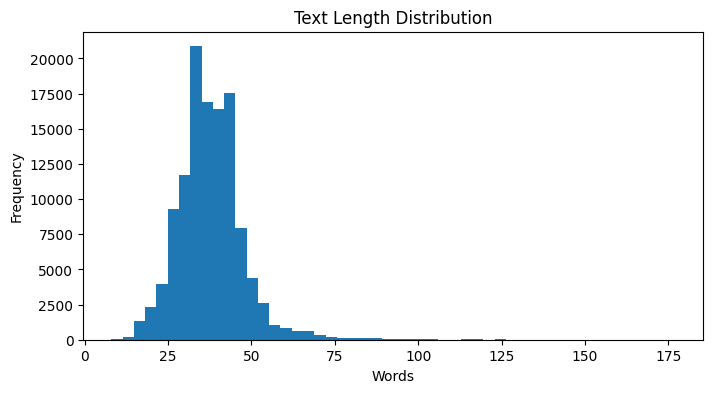

count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64

In [6]:
# 6. Basic EDA: text length
train_df["word_count"] = train_df["text"].str.split().str.len()

plt.figure(figsize=(8,4))
plt.hist(train_df["word_count"], bins=50)
plt.title("Text Length Distribution")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.show()

train_df["word_count"].describe()

## 7. Train / validation / test split

We use:
- 90% of official training data → training
- 10% of official training data → validation
- official test data → final test

The test set is not used to tune the models.

In [7]:
# 7. Split data
X_full = train_df["text"].values
y_full = train_df["label"].values

X_test = test_df["text"].values
y_test = test_df["label"].values

X_train, X_val, y_train, y_val = train_test_split(
    X_full,
    y_full,
    test_size=0.10,
    random_state=SEED,
    stratify=y_full
)

print("Training  :", len(X_train))
print("Validation:", len(X_val))
print("Test      :", len(X_test))

Training  : 108000
Validation: 12000
Test      : 7600


## 8. Text Vectorization

Raw text must be converted to integer token IDs.

```text
Raw text
   ↓
TextVectorization
   ↓
Integer tokens
   ↓
Embedding
   ↓
RNN / LSTM / GRU
   ↓
Dense + Softmax
```

The same vectorizer is used by all three models for a fair comparison.

In [8]:
# 8. Common preprocessing
VOCAB_SIZE = 20_000
MAX_LEN = 150
EMBED_DIM = 128
RNN_UNITS = 64
NUM_CLASSES = 4
BATCH_SIZE = 128
EPOCHS = 8

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN
)

# IMPORTANT: adapt only on training text
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(256)
)

actual_vocab_size = len(vectorizer.get_vocabulary())
print("Vocabulary:", actual_vocab_size)
print("Max sequence length:", MAX_LEN)

Vocabulary: 20000
Max sequence length: 150


In [9]:
# 9. Build identical train/validation/test pipelines
def make_dataset(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, shuffle=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


# 10. Model 1 — Simple RNN

Basic architecture:

```text
Text → Embedding → SimpleRNN(64) → Dense(4, softmax)
```

The RNN carries a hidden state from one time step to the next.

In [10]:
# 10. Simple RNN
def build_rnn_model():
    model = tf.keras.Sequential([
        vectorizer,
        tf.keras.layers.Embedding(actual_vocab_size, EMBED_DIM),
        tf.keras.layers.SimpleRNN(RNN_UNITS),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

rnn_model = build_rnn_model()
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ ?                      │   0 (unbuilt) │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [11]:
# 11. Train Simple RNN
rnn_history = rnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 56ms/step - accuracy: 0.6250 - loss: 0.9557 - val_accuracy: 0.7347 - val_loss: 0.7893
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.7765 - loss: 0.6923 - val_accuracy: 0.7610 - val_loss: 0.7464
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.5519 - loss: 0.9504 - val_accuracy: 0.4275 - val_loss: 1.1353
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.4285 - loss: 1.0973 - val_accuracy: 0.4234 - val_loss: 1.1327


# 12. Model 2 — LSTM

Basic architecture:

```text
Text → Embedding → LSTM(64) → Dense(4, softmax)
```

LSTM uses gates to control information flow and maintains a cell state.

In [12]:
# 12. LSTM
def build_lstm_model():
    model = tf.keras.Sequential([
        vectorizer,
        tf.keras.layers.Embedding(actual_vocab_size, EMBED_DIM),
        tf.keras.layers.LSTM(RNN_UNITS),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
# 13. Train LSTM
lstm_history = lstm_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 120s 139ms/step - accuracy: 0.2486 - loss: 1.3867 - val_accuracy: 0.2500 - val_loss: 1.3865
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 119s 141ms/step - accuracy: 0.2500 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3865
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 123s 146ms/step - accuracy: 0.2479 - loss: 1.3864 - val_accuracy: 0.2501 - val_loss: 1.3863
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 121s 143ms/step - accuracy: 0.2502 - loss: 1.3868 - val_accuracy: 0.2500 - val_loss: 1.3864
Epoch 5/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 118s 139ms/step - accuracy: 0.2487 - loss: 1.3864 - val_accuracy: 0.2503 - val_loss: 1.3863
Epoch 6/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 100s 118ms/step - accuracy: 0.2477 - loss: 1.3866 - val_accuracy: 0.2502 - val_loss: 1.3863
Epoch 7/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - accuracy: 0.2496 - loss: 1.3863 - val_accuracy: 0.2500 - val_loss: 1.3865


# 14. Model 3 — GRU

Basic architecture:

```text
Text → Embedding → GRU(64) → Dense(4, softmax)
```

GRU is a gated recurrent model with fewer gates than LSTM and no separate cell state.

In [14]:
# 14. GRU
def build_gru_model():
    model = tf.keras.Sequential([
        vectorizer,
        tf.keras.layers.Embedding(actual_vocab_size, EMBED_DIM),
        tf.keras.layers.GRU(RNN_UNITS),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

gru_model = build_gru_model()
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
# 15. Train GRU
gru_history = gru_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ]
)

Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 97ms/step - accuracy: 0.2511 - loss: 1.3867 - val_accuracy: 0.2500 - val_loss: 1.3864
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 100ms/step - accuracy: 0.2476 - loss: 1.3865 - val_accuracy: 0.2501 - val_loss: 1.3864
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 90s 107ms/step - accuracy: 0.2507 - loss: 1.3864 - val_accuracy: 0.2500 - val_loss: 1.3863
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 96ms/step - accuracy: 0.2491 - loss: 1.3864 - val_accuracy: 0.2501 - val_loss: 1.3863
Epoch 5/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 94ms/step - accuracy: 0.2485 - loss: 1.3864 - val_accuracy: 0.2501 - val_loss: 1.3863
Epoch 6/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 88s 104ms/step - accuracy: 0.2512 - loss: 1.3861 - val_accuracy: 0.2503 - val_loss: 1.3863
Epoch 7/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 89s 106ms/step - accuracy: 0.6041 - loss: 0.8320 - val_accuracy: 0.9052 - val_loss: 0.2948
Epoch 8/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 94ms/step - accuracy: 0.9220 - loss: 0.2416 - val_

# 16. Compare training histories

We compare validation accuracy and validation loss for all three models.

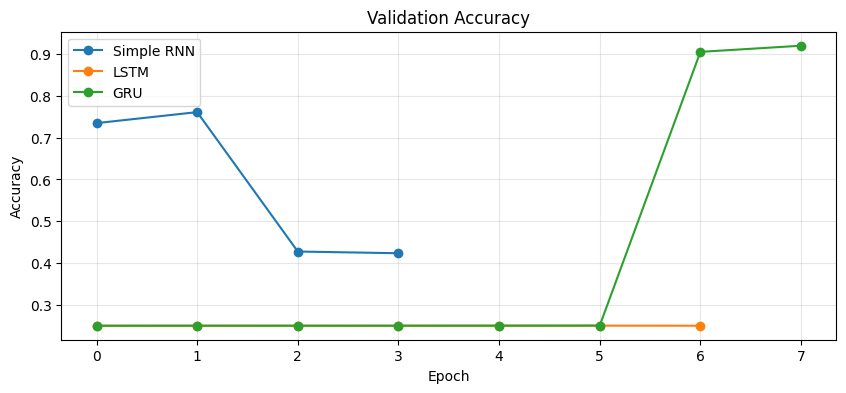

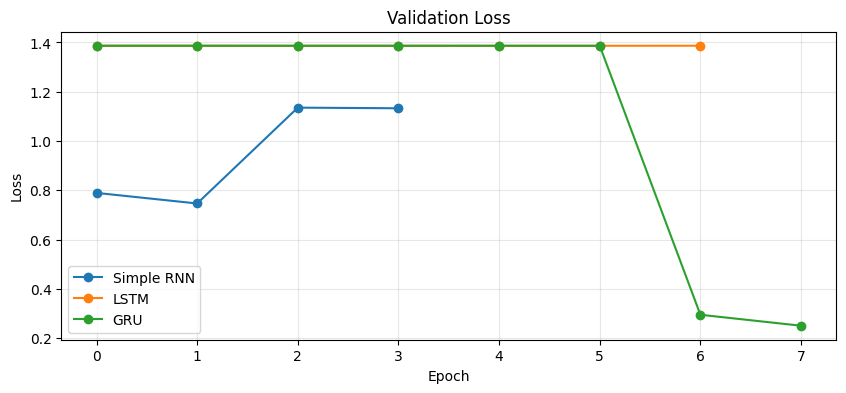

In [16]:
# 16. Plot validation accuracy and loss
plt.figure(figsize=(10,4))
plt.plot(rnn_history.history["val_accuracy"], marker="o", label="Simple RNN")
plt.plot(lstm_history.history["val_accuracy"], marker="o", label="LSTM")
plt.plot(gru_history.history["val_accuracy"], marker="o", label="GRU")
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(rnn_history.history["val_loss"], marker="o", label="Simple RNN")
plt.plot(lstm_history.history["val_loss"], marker="o", label="LSTM")
plt.plot(gru_history.history["val_loss"], marker="o", label="GRU")
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 17. Final test evaluation

We evaluate each model on the same unseen test set.

Metrics:
- **Accuracy**
- **Macro Precision**
- **Macro Recall**
- **Macro F1**
- Per-class precision/recall/F1
- Confusion matrix

Because AG News has four balanced classes, macro metrics are easy to interpret and give each class equal weight.

In [17]:
# 17. Generate predictions
def get_predictions(model, texts):
    probabilities = model.predict(np.array(texts), verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    return predictions, probabilities

rnn_pred, rnn_prob = get_predictions(rnn_model, X_test)
lstm_pred, lstm_prob = get_predictions(lstm_model, X_test)
gru_pred, gru_prob = get_predictions(gru_model, X_test)

In [18]:
# 18. Overall metric comparison
def metric_row(y_true, y_pred, name):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": p,
        "Macro Recall": r,
        "Macro F1": f1
    }

results = pd.DataFrame([
    metric_row(y_test, rnn_pred, "Simple RNN"),
    metric_row(y_test, lstm_pred, "LSTM"),
    metric_row(y_test, gru_pred, "GRU")
])

results.round(4)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Simple RNN,0.7538,0.7540,0.7538,0.7533
1,LSTM,0.2503,0.3125,0.2503,0.1005
2,GRU,0.9155,0.9161,0.9155,0.9155


In [19]:
# 19. Detailed classification reports
for name, pred in [
    ("Simple RNN", rnn_pred),
    ("LSTM", lstm_pred),
    ("GRU", gru_pred)
]:
    print("\n" + "="*65)
    print(name)
    print("="*65)
    print(classification_report(
        y_test,
        pred,
        target_names=label_names,
        digits=4,
        zero_division=0
    ))


Simple RNN
              precision    recall  f1-score   support

       World     0.7678    0.7537    0.7607      1900
      Sports     0.7917    0.8121    0.8018      1900
    Business     0.7383    0.6816    0.7088      1900
    Sci/Tech     0.7180    0.7679    0.7421      1900

    accuracy                         0.7538      7600
   macro avg     0.7540    0.7538    0.7533      7600
weighted avg     0.7540    0.7538    0.7533      7600


LSTM
              precision    recall  f1-score   support

       World     0.2501    1.0000    0.4001      1900
      Sports     0.0000    0.0000    0.0000      1900
    Business     0.0000    0.0000    0.0000      1900
    Sci/Tech     1.0000    0.0011    0.0021      1900

    accuracy                         0.2503      7600
   macro avg     0.3125    0.2503    0.1005      7600
weighted avg     0.3125    0.2503    0.1005      7600


GRU
              precision    recall  f1-score   support

       World     0.9384    0.8895    0.9133      190

# 20. Confusion matrices

Diagonal values = correct predictions.

Off-diagonal values = errors.

This lets us see which news categories are commonly confused.

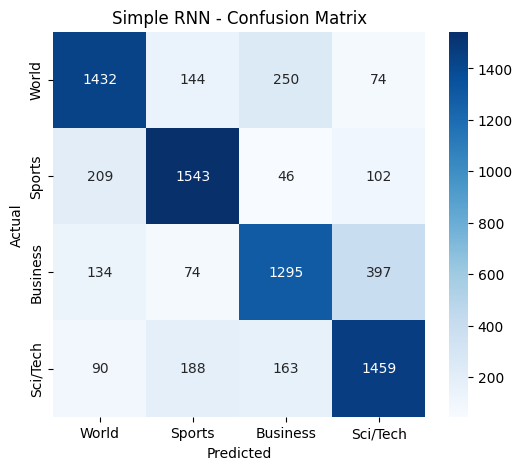

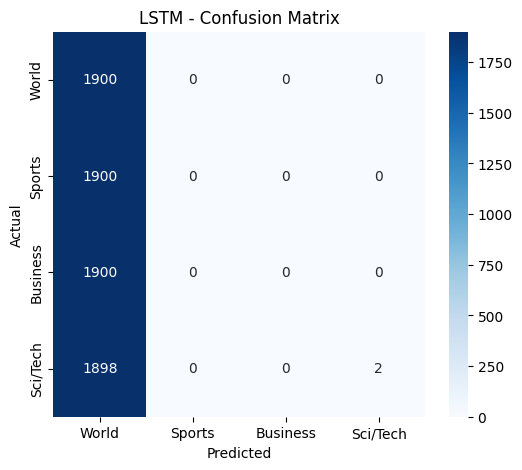

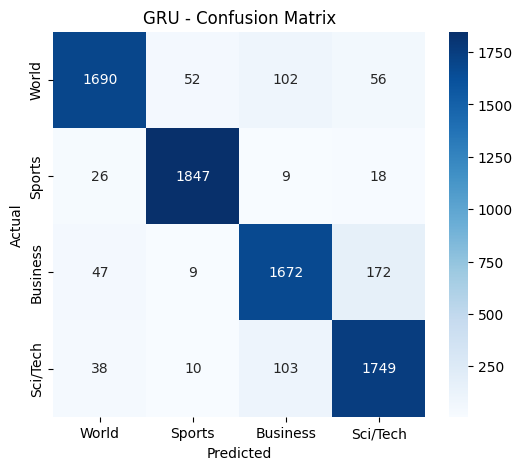

In [20]:
# 20. Confusion matrices
predictions = {
    "Simple RNN": rnn_pred,
    "LSTM": lstm_pred,
    "GRU": gru_pred
}

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_names,
        yticklabels=label_names
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

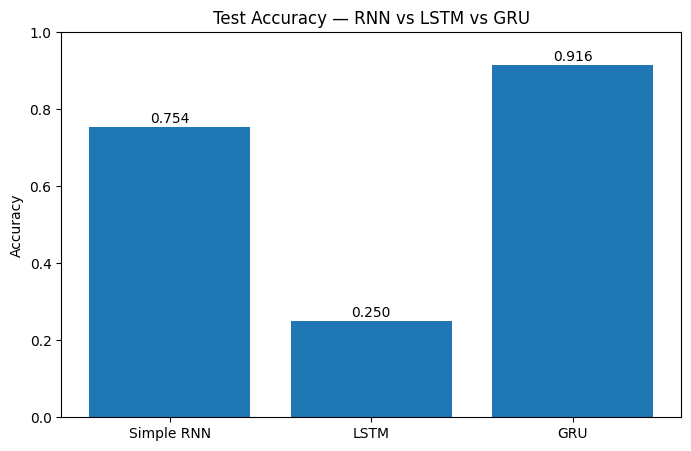

In [21]:
# 21. Accuracy comparison
plt.figure(figsize=(8,5))
bars = plt.bar(results["Model"], results["Accuracy"])
plt.title("Test Accuracy — RNN vs LSTM vs GRU")
plt.ylabel("Accuracy")
plt.ylim(0,1)

for bar, value in zip(bars, results["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.show()

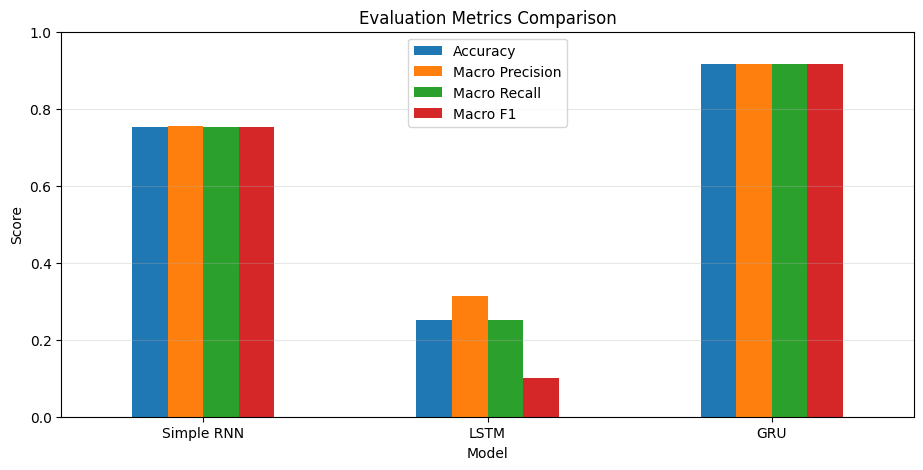

In [22]:
# 22. All evaluation metrics
results.set_index("Model")[[
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]].plot(kind="bar", figsize=(11,5))

plt.title("Evaluation Metrics Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

# 23. Parameter comparison

Parameter count helps us understand model complexity.

The recurrent layers are not equivalent internally:
- SimpleRNN has the simplest recurrent transformation.
- GRU has gates.
- LSTM has more gates and a cell state.

In [23]:
# 23. Parameter counts
parameter_results = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "GRU"],
    "Parameters": [
        rnn_model.count_params(),
        lstm_model.count_params(),
        gru_model.count_params()
    ]
})

parameter_results

,Model,Parameters
0,Simple RNN,2572612
1,LSTM,2609668
2,GRU,2597508


# 24. Training history helper

Training/validation curves help detect overfitting.

If training accuracy keeps increasing while validation accuracy stops improving or decreases, the model may be overfitting.

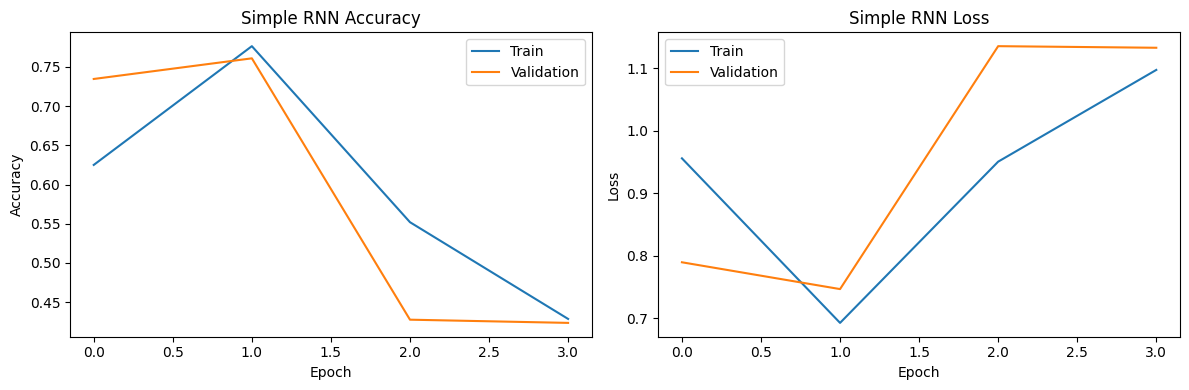

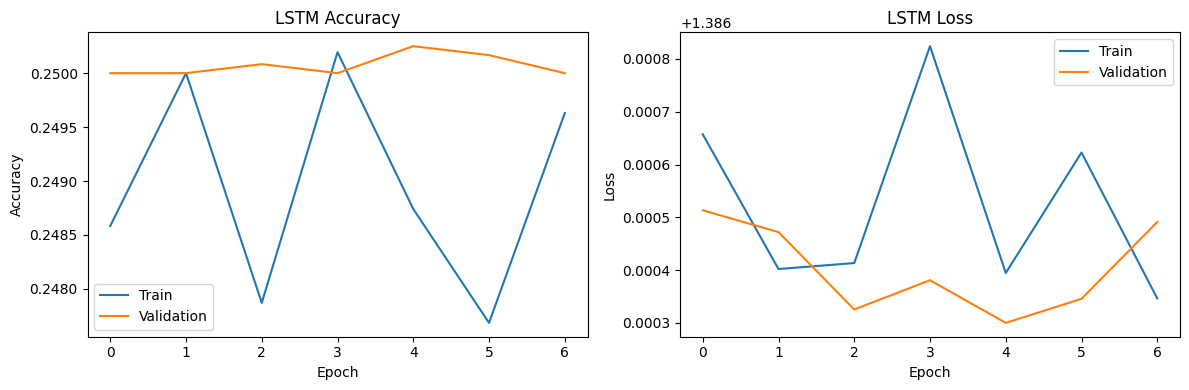

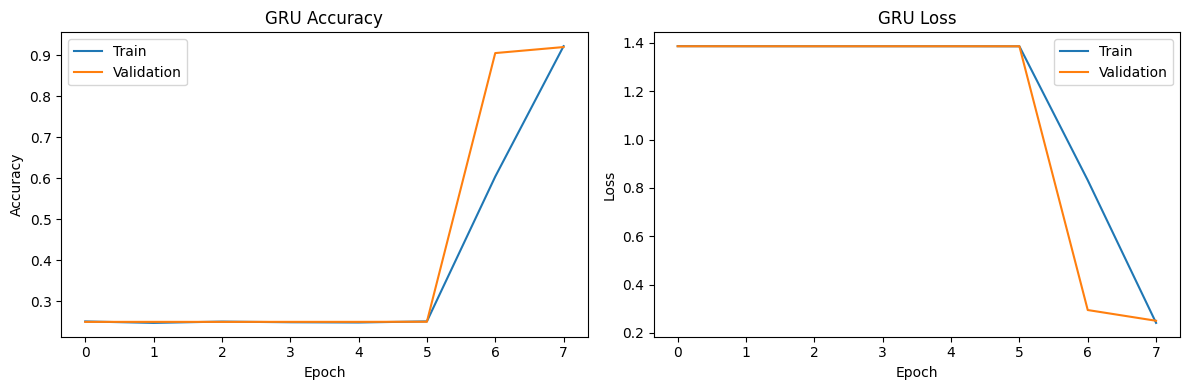

In [24]:
# 24. Reusable history plot
def plot_history(history, name):
    h = history.history

    plt.figure(figsize=(12,4))

    plt.subplot(1,2,1)
    plt.plot(h["accuracy"], label="Train")
    plt.plot(h["val_accuracy"], label="Validation")
    plt.title(name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(h["loss"], label="Train")
    plt.plot(h["val_loss"], label="Validation")
    plt.title(name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(rnn_history, "Simple RNN")
plot_history(lstm_history, "LSTM")
plot_history(gru_history, "GRU")

# 25. Error analysis

Do not stop at the accuracy number.

Look at examples that were misclassified and ask:
- Is the text ambiguous?
- Are two categories semantically similar?
- Does the text require long context?
- Did different models make different mistakes?

In [25]:
# 25. Show a few incorrect predictions
def show_errors(df, y_true, y_pred, model_name, n=10):
    idx = np.where(y_true != y_pred)[0][:n]
    rows = []

    for i in idx:
        rows.append({
            "Text": df.iloc[i]["text"],
            "Actual": label_names[y_true[i]],
            "Predicted": label_names[y_pred[i]]
        })

    print(model_name)
    return pd.DataFrame(rows)

display(show_errors(test_df, y_test, rnn_pred, "Simple RNN"))
display(show_errors(test_df, y_test, lstm_pred, "LSTM"))
display(show_errors(test_df, y_test, gru_pred, "GRU"))

Simple RNN


,Text,Actual,Predicted
0,The Race is On: Second Private Team Sets Launc...,Sci/Tech,Sports
1,Prediction Unit Helps Forecast Wildfires (AP) ...,Sci/Tech,Sports
2,"Loosing the War on Terrorism \\""Sven Jaschan, ...",Sci/Tech,World
3,"FOAFKey: FOAF, PGP, Key Distribution, and Bloo...",Sci/Tech,Business
4,"Card fraud unit nets 36,000 cards In its first...",Sci/Tech,Business
5,Dutch Retailer Beats Apple to Local Download M...,Sci/Tech,Sports
6,Socialites unite dolphin groups Dolphin groups...,Sci/Tech,Sports
7,Sun's Looking Glass Provides 3D View Developer...,Sci/Tech,Sports
8,Rivals Try to Turn Tables on Charles Schwab By...,Sci/Tech,Sports
9,They've caught his eye In quot;helping themse...,Sports,Sci/Tech


LSTM


,Text,Actual,Predicted
0,Fears for T N pension after talks Unions repre...,Business,World
1,The Race is On: Second Private Team Sets Launc...,Sci/Tech,World
2,Ky. Company Wins Grant to Study Peptides (AP) ...,Sci/Tech,World
3,Prediction Unit Helps Forecast Wildfires (AP) ...,Sci/Tech,World
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,Sci/Tech,World
5,"Loosing the War on Terrorism \\""Sven Jaschan, ...",Sci/Tech,World
6,"FOAFKey: FOAF, PGP, Key Distribution, and Bloo...",Sci/Tech,World
7,E-mail scam targets police chief Wiltshire Pol...,Sci/Tech,World
8,"Card fraud unit nets 36,000 cards In its first...",Sci/Tech,World
9,Group to Propose New High-Speed Wireless Forma...,Sci/Tech,World


GRU


,Text,Actual,Predicted
0,"Card fraud unit nets 36,000 cards In its first...",Sci/Tech,Business
1,Some People Not Eligible to Get in on Google I...,Sci/Tech,Business
2,Rivals Try to Turn Tables on Charles Schwab By...,Sci/Tech,Business
3,Venezuela Prepares for Chavez Recall Vote Supp...,World,Business
4,India's Tata expands regional footprint via Na...,World,Business
5,Live: Olympics day four Richard Faulds and Ste...,World,Sports
6,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
7,"U.S. Misses Cut in Olympic 100 Free ATHENS, Gr...",World,Sports
8,Stocks Climb on Drop in Consumer Prices NEW YO...,World,Business
9,Yahoo! Ups Ante for Small Businesses Web giant...,Business,Sci/Tech


# 26. New-text inference

The trained model can now classify text it has never seen before.

In [26]:
# 26. Predict new news text
new_texts = [
    "The football team won the championship after a dramatic final.",
    "The company reported higher quarterly profits after strong sales.",
    "Scientists announced a breakthrough in computer technology.",
    "The government announced a new international agreement."
]

def predict_new_text(model, texts):
    probs = model.predict(np.array(texts), verbose=0)
    preds = np.argmax(probs, axis=1)

    return pd.DataFrame({
        "Text": texts,
        "Prediction": [label_names[p] for p in preds],
        "Confidence": np.max(probs, axis=1)
    })

display(predict_new_text(rnn_model, new_texts))
display(predict_new_text(lstm_model, new_texts))
display(predict_new_text(gru_model, new_texts))

ValueError: Invalid dtype: str2080

# 27. Save models and results

Saving the models allows later inference without retraining.

In [ ]:
# 27. Save trained models and comparison results
os.makedirs("saved_models", exist_ok=True)
os.makedirs("results", exist_ok=True)

rnn_model.save("saved_models/rnn_ag_news.keras")
lstm_model.save("saved_models/lstm_ag_news.keras")
gru_model.save("saved_models/gru_ag_news.keras")

results.to_csv("results/model_comparison.csv", index=False)
parameter_results.to_csv("results/parameter_comparison.csv", index=False)

print("Saved models and results.")

# 28. Core code comparison

These are the basic recurrent architectures you asked for.

### Simple RNN
```python
model = Sequential([
    Embedding(vocab_size, 128),
    SimpleRNN(64),
    Dense(num_classes, activation="softmax")
])
```

### LSTM
```python
model = Sequential([
    Embedding(vocab_size, 128),
    LSTM(64),
    Dense(num_classes, activation="softmax")
])
```

### GRU
```python
model = Sequential([
    Embedding(vocab_size, 128),
    GRU(64),
    Dense(num_classes, activation="softmax")
])
```

In this notebook, `TextVectorization` is placed before `Embedding` so raw text can be passed directly to the model.

# 29. Algorithm summary

## Simple RNN
```text
x_t + previous hidden state
          ↓
     Simple RNN cell
          ↓
      new hidden state
```

High-level equation:
```text
h_t = activation(W_x x_t + W_h h_(t-1) + b)
```

## LSTM
```text
Previous state + current input
          ↓
   Forget / Input / Output gates
          ↓
      Cell + hidden state
```

## GRU
```text
Previous hidden state + current input
          ↓
      Update / Reset gates
          ↓
       New hidden state
```

## Output
For four classes:
```python
Dense(4, activation="softmax")
```

Softmax produces four class probabilities.

# 30. What to compare and how to interpret it

| Item | Simple RNN | LSTM | GRU |
|---|---|---|---|
| Basic recurrent model | Yes | No | No |
| Gates | No | Yes | Yes |
| Separate cell state | No | Yes | No |
| Main advantage | Simplicity | Long-term memory handling | Gated memory with simpler structure |
| Parameters | Usually fewer | Usually more | Usually between RNN and LSTM |
| Evaluation | Same test set | Same test set | Same test set |

**Important:** The model with the highest score in this particular experiment is not automatically the universally best recurrent architecture. Results depend on the dataset and training configuration.

# 31. Beginner exercises

1. Change `RNN_UNITS = 64` to `32` and retrain all three.
2. Change `MAX_LEN = 150` to `100`.
3. Change `EMBED_DIM = 128` to `64`.
4. Add `Dropout(0.3)` after each recurrent layer.
5. Change Adam to SGD.
6. Compare training epochs before and after EarlyStopping.
7. Find three examples where RNN and LSTM disagree.
8. Find three examples where LSTM and GRU disagree.
9. Explain which class has the lowest F1 for each model.
10. Write your own conclusion from the metric table.

# 32. Viva / interview questions

1. What is a sequence?
2. Why is RNN useful for text?
3. What is a hidden state?
4. Why can basic RNNs suffer from vanishing gradients?
5. Why was LSTM introduced?
6. What does the forget gate do?
7. What does the input gate do?
8. What does the output gate do?
9. What is the main difference between LSTM and GRU?
10. Does GRU have a separate cell state?
11. Why do we use Embedding?
12. Why do we use softmax?
13. Why use sparse categorical crossentropy?
14. Why keep test data separate?
15. What is validation data?
16. What does EarlyStopping do?
17. Why evaluate precision, recall and F1 in addition to accuracy?
18. What does a confusion matrix show?
19. Why must preprocessing be consistent for a fair comparison?
20. Does the highest validation accuracy guarantee the highest test accuracy?

# 33. Final project workflow

```text
AG News
   ↓
EDA
   ↓
Train / Validation / Test
   ↓
TextVectorization
   ↓
Embedding
   ↓
 ┌──────────┬──────────┬──────────┐
 ↓          ↓          ↓
RNN       LSTM        GRU
 ↓          ↓          ↓
 └──────────┴──────────┘
            ↓
       Same Test Set
            ↓
 Accuracy / Precision / Recall / F1
            ↓
       Confusion Matrix
            ↓
     Parameter Comparison
            ↓
        Error Analysis
            ↓
      New Text Prediction
```

### Next progression

**Project 2:** LSTM/GRU + Attention  
**Project 3:** LSTM/GRU time-series forecasting  
**Project 4:** deployment with FastAPI + Docker + MLflow

First become comfortable with this three-model comparison before moving to Attention or Transformers.